# 04 · Data experiments: what kind of extra training data helps across datasets?

Architectures: the best CNN and the best transformer by E1 A-validation loss (see 03). Hyper-parameters, step budget, early-stopping rule, validation set and threshold rule are identical across all experiments here. **Only the training data changes.**

| ID | Training data | Question |
|---|---|---|
| E1 | 1,000 real A (500/class) | baseline |
| E2 | E1 + conventional augmentation | cheap augmentation |
| E3 / E4 | E1 + 25% / 50% synthetic A | generative augmentation (teammate's generator) |
| R25 / R50 | 1,250 / 1,500 real A (superset of E1) | **matched control for E3/E4**: what would 250/500 *real* images buy? |
| N250 · N500 · N2000 | 250 / 500 / 2,000 real A | real-data scaling curve |
| FULL / FULL_AUG | all 4.1k real A train images (≈72% pneumonia), ± augmentation | upper reference with all available source data |

Primary outcome: **Δ AUROC on external B (opacity vs normal)** relative to E1. Robustness: the same Δ *within* AP and within PA films (view is a strong confounder in B, see 03). Test A is reported alongside. A change that helps A but not B improves in-domain fit, not generalisation.

### Why the matched real-data controls matter
"Synthetic data improved B by +0.02" means little on its own: almost *any* extra training data might do that. The question is whether a synthetic image is worth as much as a real one. R25/R50 add exactly as many **real** A images as E3/E4 add synthetic ones (the same balanced, one-per-patient sampling; E1's images are a subset of R25's, which are a subset of R50's). Possible readings:

| Outcome | Interpretation |
|---|---|
| E3/E4 ≈ R25/R50 > E1 | synthetic images are about as useful as real ones: generative augmentation is a viable substitute when real data is scarce |
| R25/R50 > E3/E4 > E1 | synthetic data helps, but less than real data |
| E3/E4 ≈ E1 | no measurable effect at this scale |
| E3/E4 < E1 | synthetic data hurts (artefacts, label noise or reinforced shortcuts) |
| E3/E4 > R25/R50 | synthetic data adds something real data from A does not (e.g. more diversity), or, if the generator was trained on all A images, it is transferring information from images the classifier never saw (see `docs/SYNTHETIC_DATA.md`) |

The project plan's three scenarios map onto this: (A) helps on A and B, (B) helps on A only, (C) hurts.

### The scaling curve
N250 → N500 → E1 (1k) → R25 → R50 → N2000 (all balanced), plus FULL (all 4.1k images, imbalanced). If B performance plateaus while Test A keeps improving, more data from *the same hospital* mainly teaches hospital-specific features. Then more of the same, real or synthetic, cannot be expected to fix external generalisation. Diversity (other sources, or augmentations that break acquisition cues) would be needed instead.

### Caveats
* All real controls come from A and carry A's shortcut, so they cannot help with a shift that A does not contain.
* FULL is imbalanced (≈72% pneumonia) and changes class balance as well as size; FULL vs N2000 isolates mostly the imbalance + 2k extra pneumonia images.
* Two architectures × three seeds: small effects (|Δ| < 0.01) are below the resolution of this study.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "reports/results"; RES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)

from cxr.analysis import collect_runs, mean_sd, compare, strata_runs, EVAL_LABELS, STRATA_LABELS
ALL_LABELS = {**EVAL_LABELS, **STRATA_LABELS}
runs = collect_runs()
sel = json.loads((ROOT / "configs/selected_archs.json").read_text())["selected"]
EXPS = ["N250", "N500", "E1", "R25", "R50", "N2000", "FULL", "E2", "FULL_AUG", "E3", "E4"]
synth_exps = [e for e in ["E3_sd_lora", "E4_sd_lora"] if e in set(runs.experiment)]  # teammate's generator (07 has the variants)
EXPS = [e for e in EXPS if e in set(runs.experiment) and not e.startswith(("E3", "E4"))] + synth_exps
d = runs[runs.arch.isin(sel) & runs.experiment.isin(EXPS)]
print("selected:", sel, "| experiments with results:", sorted(set(d.experiment)))
if not synth_exps:
    display(Markdown("> **E3/E4 pending:** the synthetic images from the generative component are not available yet. "
                     "The pipeline is ready (`docs/SYNTHETIC_DATA.md`); the real-data controls R25/R50 below set the bar a synthetic image has to clear."))

/home/edelweizse/Projects/uni/AIE/final/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


selected: ['efficientnet_b0', 'vit_small'] | experiments with results: ['E1', 'E2', 'E3_sd_lora', 'E4_sd_lora', 'FULL', 'FULL_AUG', 'N2000', 'N250', 'N500', 'R25', 'R50']


## Results table

In [2]:
tabs = []
for key, lab in EVAL_LABELS.items():
    t = mean_sd(d[d["eval"] == key], ["arch", "experiment"], ["auroc", "sensitivity", "specificity"])
    tabs.append(t.drop(columns="seeds").add_prefix(f"{lab} | "))
n = d.drop_duplicates(["arch", "experiment"]).set_index(["arch", "experiment"]).n_train.rename("n_train")
strata = strata_runs(d)
for key, lab in STRATA_LABELS.items():
    t = mean_sd(strata[strata["eval"] == key], ["arch", "experiment"], ["auroc"])
    tabs.append(t.drop(columns="seeds").add_prefix(f"{lab} | "))
table = pd.concat([n] + tabs, axis=1)
table = table.reindex(pd.MultiIndex.from_product([sel, EXPS])).dropna(how="all")
table.to_csv(RES / "data_experiments.csv")
display(table[[c for c in table if c == "n_train" or "auroc" in c]])

n_train Kermany test (internal) | auroc RSNA: opacity vs normal | auroc RSNA: opacity vs all | auroc RSNA PA only: opacity vs normal | auroc  \
efficientnet_b0 N250            250                   0.944 ± 0.004                   0.843 ± 0.011                0.730 ± 0.009                           0.738 ± 0.010   
                N500            500                   0.939 ± 0.012                   0.863 ± 0.010                0.738 ± 0.003                           0.778 ± 0.030   
                E1             1000                   0.937 ± 0.005                   0.859 ± 0.004                0.736 ± 0.002                           0.767 ± 0.019   
                R25            1250                   0.888 ± 0.073                   0.863 ± 0.027                0.734 ± 0.026                           0.764 ± 0.016   
                R50            1500                   0.885 ± 0.043                   0.865 ± 0.032                0.744 ± 0.017                           0.762 ± 0.056   
                N2000          2000                   0.887 ± 0.013                   0.867 ± 0.017                0.748 ± 0.014                           0.766 ± 0.028   
                FULL           4093                   0.891 ± 0.040                   0.878 ± 0.011                0.756 ± 0.013                           0.777 ± 0.011   
                E2             1000                   0.932 ± 0.032                   0.915 ± 0.010                0.778 ± 0.015                           0.843 ± 0.011   
                FULL_AUG       4093                   0.955 ± 0.013                   0.916 ± 0.008                0.785 ± 0.006                           0.849 ± 0.018   
                E3_sd_lora     1250                   0.902 ± 0.034                   0.819 ± 0.008                0.709 ± 0.011                           0.731 ± 0.013   
                E4_sd_lora     1500                   0.894 ± 0.072                   0.787 ± 0.065                0.685 ± 0.056                           0.684 ± 0.032   
vit_small       N250            250                   0.913 ± 0.048                   0.753 ± 0.059                0.665 ± 0.045                           0.635 ± 0.016   
                N500            500                   0.903 ± 0.068                   0.794 ± 0.058                0.692 ± 0.047                           0.662 ± 0.047   
                E1             1000                   0.866 ± 0.075                   0.823 ± 0.016                0.711 ± 0.016                           0.707 ± 0.007   
                R25            1250                   0.849 ± 0.053                   0.852 ± 0.037                0.730 ± 0.028                           0.745 ± 0.042   
                R50            1500                   0.885 ± 0.008                   0.863 ± 0.015                0.744 ± 0.011                           0.742 ± 0.020   
                N2000          2000                   0.740 ± 0.053                   0.848 ± 0.033                0.732 ± 0.031                           0.737 ± 0.027   
                FULL           4093                   0.855 ± 0.034                   0.887 ± 0.011                0.765 ± 0.014                           0.781 ± 0.008   
                E2             1000                   0.926 ± 0.040                   0.867 ± 0.062                0.745 ± 0.040                           0.757 ± 0.092   
                FULL_AUG       4093                   0.899 ± 0.030                   0.913 ± 0.005                0.784 ± 0.005                           0.814 ± 0.011   
                E3_sd_lora     1250                   0.930 ± 0.032                   0.809 ± 0.041                0.706 ± 0.037                           0.663 ± 0.038   
                E4_sd_lora     1500                   0.883 ± 0.039                   0.804 ± 0.017                0.704 ± 0.017                           0.645 ± 0.026   

                           RSNA AP only: opacity vs normal | auroc  
ef

## Effect of each data intervention relative to E1 (paired bootstrap)

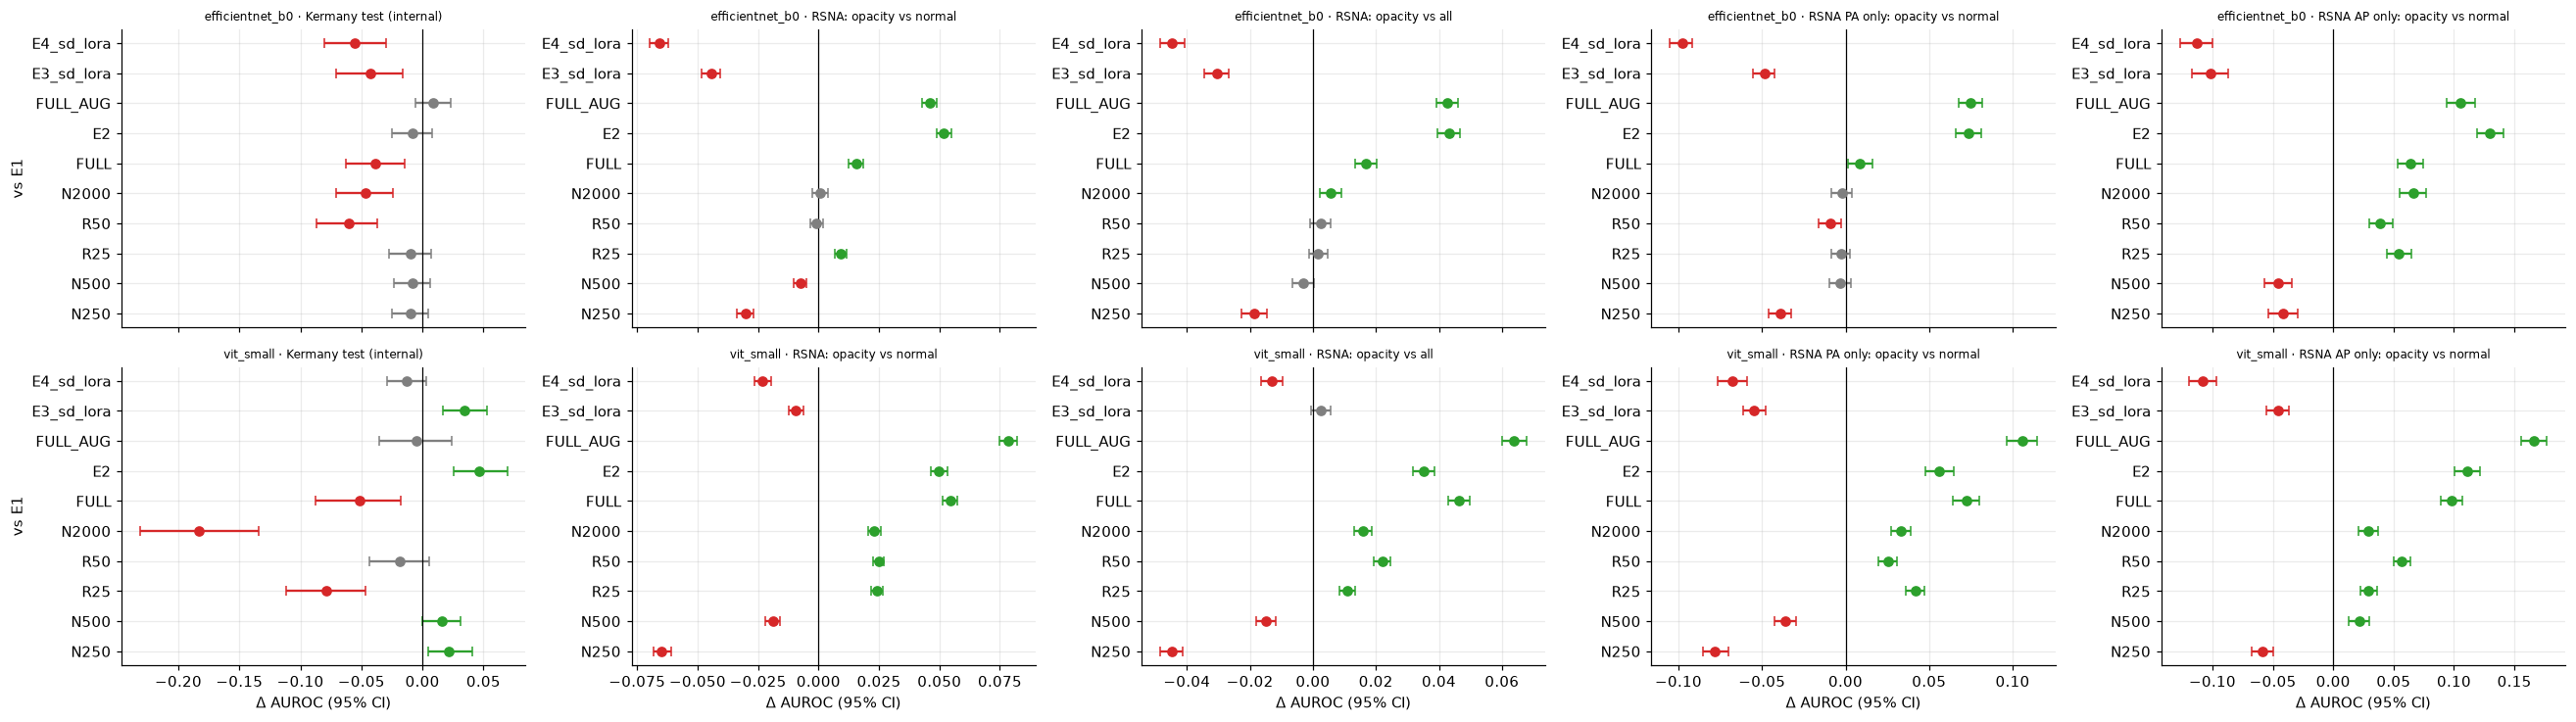

ci_hi                                                                                                               \
eval                       Kermany test (internal) RSNA AP only: opacity vs normal RSNA PA only: opacity vs normal RSNA: opacity vs all RSNA: opacity vs normal   
arch            to                                                                                                                                                
efficientnet_b0 E2                           0.008                           0.141                           0.081                0.047                   0.055   
                E3_sd_lora                  -0.017                          -0.087                          -0.042               -0.027                  -0.041   
                E4_sd_lora                  -0.030                          -0.100                          -0.092               -0.041                  -0.062   
                FULL                        -0.015                           0.074                           0.016                0.020                   0.019   
                FULL_AUG                     0.023                           0.117                           0.082                0.046                   0.049   
                N2000                       -0.024                           0.077                           0.004                0.009                   0.004   
                N250                         0.005                          -0.030                          -0.032               -0.015                  -0.027   
                N500                         0.007                          -0.034                           0.003                0.000                  -0.005   
                R25                          0.007                           0.064                           0.003                0.005                   0.012   
                R50                         -0.037                           0.049                          -0.003                0.006                   0.002   
vit_small       E2                           0.069                           0.121                           0.065                0.039                   0.053   
                E3_sd_lora                   0.053                          -0.037                          -0.048                0.005                  -0.006   
                E4_sd_lora                   0.003                          -0.097                          -0.059               -0.010                  -0.020   
                FULL                        -0.018                           0.107                           0.080                0.050                   0.057   
                FULL_AUG                     0.024                           0.177                           0.115                0.068                   0.082   
                N2000                       -0.134                           0.038                           0.039                0.019                   0.026   
                N250                         0.041                          -0.049                          -0.070               -0.041                  -0.061   
                N500                         0.031                           0.030                          -0.030               -0.012                  -0.016   
                R25                         -0.047                           0.036                           0.047                0.013                   0.027   
                R50                          0.005                           0.064                           0.031                0.025                   0.027   

                                             ci_lo                                                                                                               \
eval                       Kermany test (internal) RSNA AP only: opacity vs normal RSNA PA only: opacity vs normal RSNA: opacity vs 

In [3]:
rows = [compare("E1", e, arch, key) for arch in sel for e in EXPS if e != "E1" for key in ALL_LABELS]
deltas = pd.DataFrame([r for r in rows if r])
deltas.to_csv(RES / "data_experiments_vs_e1.csv", index=False)
fig, axes = plt.subplots(len(sel), 5, figsize=(24, 3.4 * len(sel)), squeeze=False, sharex="col")
for i, arch in enumerate(sel):
    for j, key in enumerate(ALL_LABELS):
        x = deltas[(deltas.arch == arch) & (deltas["eval"] == key)].set_index("to").reindex([e for e in EXPS if e != "E1"]).dropna(subset=["delta_ensemble"])
        y = np.arange(len(x))
        colors = ["tab:green" if lo > 0 else "tab:red" if hi < 0 else "tab:gray" for lo, hi in zip(x.ci_lo, x.ci_hi)]
        for yy, (dlt, lo, hi), c in zip(y, x[["delta_ensemble", "ci_lo", "ci_hi"]].to_numpy(), colors):
            axes[i, j].errorbar([dlt], [yy], xerr=[[dlt - lo], [hi - dlt]], fmt="o", color=c, capsize=3)
        axes[i, j].axvline(0, color="k", lw=0.8); axes[i, j].set_yticks(y, x.index)
        axes[i, j].set_title(f"{arch} · {ALL_LABELS[key]}", fontsize=8)
    axes[i, 0].set_ylabel("vs E1")
for ax in axes[-1]: ax.set_xlabel("Δ AUROC (95% CI)")
plt.tight_layout(); plt.savefig(FIG / "data_experiments_delta.png", bbox_inches="tight"); plt.show()
display(deltas.assign(eval=deltas["eval"].map(ALL_LABELS)).pivot_table(index=["arch", "to"], columns="eval",
        values=["delta_ensemble", "ci_lo", "ci_hi"]).round(3))

### Important: two kinds of uncertainty
The bootstrap CIs on B are very narrow (±0.003–0.01) because B has 17k images. They capture *test-set sampling* only. The dominant uncertainty here is *training randomness*: across seeds, B AUROC moves by SD 0.01–0.03 within one configuration (see the table above). Practical rule for this notebook: **differences smaller than about 0.02 AUROC are inconclusive, even when the bootstrap CI excludes 0.** Compare `delta_per_seed_mean` (ps) with the ensemble Δ, and trust effects where both agree and exceed about 0.02.

**How to read the Δ plot.** Each row is an intervention compared with E1 on the same test set; the dot is Δ AUROC (seed-averaged) with a 95% paired, patient-clustered bootstrap CI. Green means the CI is above 0, red below 0, grey that it includes 0. The right-hand panels (within PA, within AP) answer whether the gain is real opacity detection or better recognition of AP-vs-PA acquisition.

## Real-data scaling: does more *real* source data transfer to B?

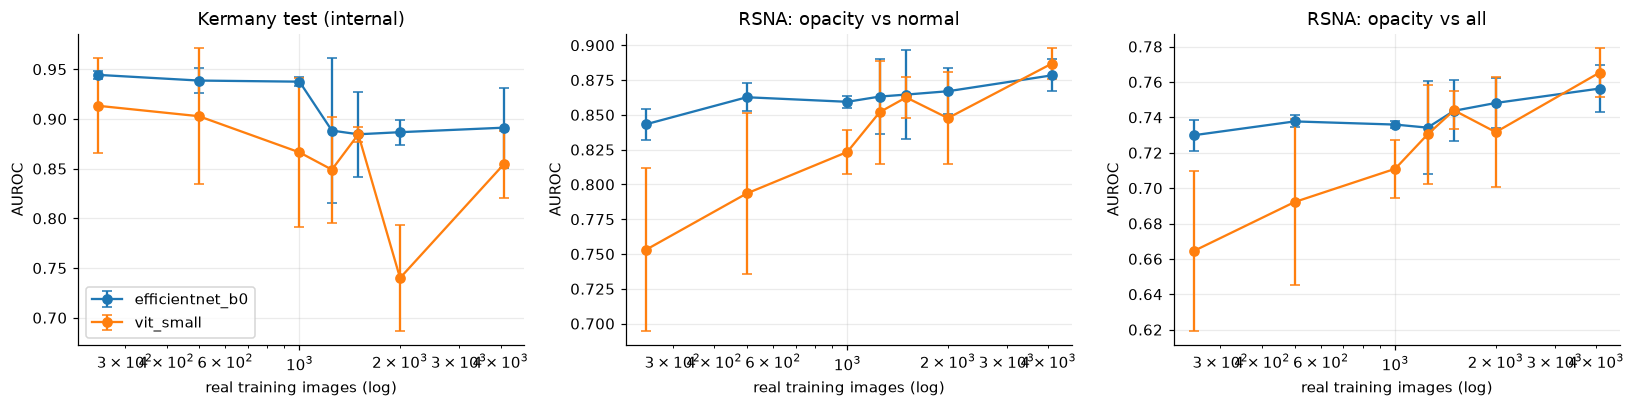

In [4]:
scal = d[d.experiment.isin(["N250", "N500", "E1", "R25", "R50", "N2000", "FULL"])]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
for ax, key in zip(axes, EVAL_LABELS):
    for arch in sel:
        s = scal[(scal.arch == arch) & (scal["eval"] == key)].groupby("n_train").auroc.agg(["mean", "std"])
        ax.errorbar(s.index, s["mean"], yerr=s["std"], marker="o", capsize=3, label=arch)
    ax.set_xscale("log"); ax.set_xlabel("real training images (log)"); ax.set_title(EVAL_LABELS[key]); ax.set_ylabel("AUROC")
axes[0].legend(); plt.tight_layout(); plt.savefig(FIG / "real_data_scaling.png", bbox_inches="tight"); plt.show()

**How to read the scaling plot.** x is the number of real training images (log scale); points are mean ± SD over 3 seeds. Compare the slope on Test A with the slope on B. A curve that keeps rising on A but flattens on B is the signature of source-specific learning.

## Operating point on B: sensitivity / specificity at the frozen A-validation threshold
AUROC says whether the model *can* separate the classes. The frozen-threshold numbers say what happens if it is deployed unchanged. Typically the A threshold is too low for B: sensitivity stays high, but specificity collapses, because B's normals look "more abnormal" to an A-trained model than A's normals did.

In [5]:
op = d[d["eval"] == "B_external:label"].groupby(["arch", "experiment"])[["sensitivity", "specificity", "threshold"]].mean()
display(op.reindex(pd.MultiIndex.from_product([sel, EXPS])).dropna().round(3))

sensitivity  specificity  threshold
efficientnet_b0 N250              0.902        0.593      0.617
                N500              0.897        0.633      0.829
                E1                0.895        0.612      0.544
                R25               0.834        0.755      0.805
                R50               0.793        0.779      0.550
                N2000             0.809        0.755      0.503
                FULL              0.698        0.877      0.726
                E2                0.818        0.851      0.698
                FULL_AUG          0.856        0.818      0.785
                E3_sd_lora        0.900        0.599      0.754
                E4_sd_lora        0.923        0.487      0.619
vit_small       N250              0.969        0.163      0.714
                N500              0.940        0.303      0.771
                E1                0.877        0.564      0.943
                R25               0.880        0.624      0.630
                R50               0.828        0.735      0.792
                N2000             0.876        0.636      0.868
                FULL              0.883        0.703      0.586
                E2                0.794        0.749      0.802
                FULL_AUG          0.813        0.877      0.894
                E3_sd_lora        0.876        0.528      0.776
                E4_sd_lora        0.812        0.660      0.949

## Insights

**1. Conventional augmentation on 1k images beats 4× more real data (EfficientNet-B0).**
B AUROC: E1 0.859 → FULL (4,093 real images) 0.878 (Δ +0.016–0.019) vs E2 (1,000 images + augmentation) 0.915 (Δ +0.052–0.056). Adding real data *on top of* augmentation (FULL_AUG 0.916) gives nothing further. For this model, the bottleneck for external performance is not the amount of source data but its *lack of variation*.

**2. ViT-S is data-hungry, and data and augmentation are complementary.** ViT gains steadily with real data (B: 0.753 at 250 → 0.823 at 1k → 0.887 at 4.1k) and from augmentation (E2 0.867). Both together give the best ViT result: FULL_AUG 0.913 (Δ +0.078–0.090 vs E1). Weak-inductive-bias models need both more examples and invariance-inducing augmentation.

**3. The bar for synthetic data (E3/E4), from the matched real controls:**
| | +25% real (R25) Δ B | +50% real (R50) Δ B |
|---|---|---|
| EfficientNet-B0 | +0.004 … +0.009 (≈ 0) | −0.001 … +0.005 (≈ 0) |
| ViT-S | +0.024 … +0.029 | +0.025 … +0.039 |

For EfficientNet-B0, 250–500 extra *real* A images do not measurably help B. Synthetic images derived from A can only beat that if they add *variation* that real A images lack, not just more of the same. For ViT, synthetic data would need to match about +0.025 to be worth as much as real data. And any E3/E4 should also be compared with **E2** (+0.05): synthetic augmentation that does not beat simple conventional augmentation has no practical case.

**3b. The synthetic images (E3/E4) fail that bar for both architectures.** Δ RSNA AUROC vs E1 (seed ensemble, 95% CI):
| | E3 (+250 synthetic) | E4 (+500 synthetic) | R25 / R50 (same number of real) | E2 (augmentation) |
|---|---|---|---|---|
| EfficientNet-B0 | −0.044 [−0.048, −0.041] | −0.066 [−0.070, −0.062] | +0.009 / −0.001 | +0.052 |
| ViT-S | −0.009 [−0.012, −0.006] | −0.023 [−0.027, −0.020] | +0.024 / +0.025 | +0.050 |

Within view the loss is larger (EfficientNet E4: PA −0.098, AP −0.113; ViT E4: PA −0.068, AP −0.108), so the synthetic images do not
just shift the AP/PA balance. They also do not help Test A (EfficientNet −0.043 / −0.055). The outcome is the last-but-one row of the
readings table above: **synthetic data hurts.** Why, and whether anything rescues it, is the subject of notebook 07 (the generator
copies Kermany's image-quality shortcut; all seven architectures lose).

**4. More real data mainly improves AP films.** For EfficientNet-B0, R25/R50/N2000/FULL raise *AP-only* AUROC by +0.04–0.09 but leave *PA-only* AUROC flat (−0.01…+0.01). The extra real images help with the harder, sicker-patient acquisition type. Augmentation improves both views (PA +0.07, AP +0.12).

**5. Test A is not a reliable "internal" yardstick.** More real training data often *lowers* Test A AUROC (EfficientNet N2000 −0.047, R50 −0.060; ViT N2000 −0.18, with large seed variance), while B improves. Combined with the shortcut finding (notebook 01: Test A was assembled differently from train/val), a plausible explanation is that more A data strengthens reliance on acquisition cues that only partly hold in the official test set. This is a hypothesis; it would need controlled experiments to confirm.

**6. The real-data scaling curve on B is shallow for CNNs and steeper for ViT.** EfficientNet-B0: 0.843 (250) → 0.878 (4,093), about +0.009 per doubling. ViT-S: 0.753 → 0.887, about +0.03 per doubling. Below about 500 images ViT is clearly worse than the CNN; at full data the two converge (0.878 vs 0.887).

**7. The frozen operating point is fragile.** The A-validation Youden threshold varies widely between runs (0.50–0.94), because A-validation is nearly perfectly separable and many thresholds look equivalent there. On B this translates into large swings between sensitivity and specificity (EfficientNet FULL: 0.70 / 0.88; ViT N250: 0.97 / 0.16). E2 and FULL_AUG give the most balanced operating points (about 0.82–0.86 / 0.82–0.88). Any deployment would need local recalibration of the threshold. AUROC is the right primary comparison metric.

**Overall answer so far.** Within this study, the most effective lever for cross-dataset generalisation is **training-time variation (augmentation)**, not data quantity. The real controls show that "more of the same source" saturates quickly for an efficient CNN. That sets a demanding but clear bar for the synthetic data: it must introduce useful variation, not just volume. The
synthetic images from the generator do not clear it: they cost 0.01–0.07 AUROC where real images and augmentation gain (3b).